Practice Math and Coding for coupling two Oscillations

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from mpl_toolkits.mplot3d import Axes3D
import os

Import Hessian Data

In [ ]:
class Hessian:
    '''Adapted from Indu's LLM generated code
    '''
    def __init__(self, file_path):
        self.file_path=file_path
        self.hess_dict={}
        
        with open(file_path, 'r') as file:
            contents=file.readlines()
            i=0
            while i<len(contents):
                
                if contents[i].strip()=='$vibrational_frequencies':
                    j=2
                    freqs=[]
                    while contents[i+j].strip()!='':
                        freqs.append(float(contents[i+j].split()[1]))
                        j+=1
                        self.hess_dict['vibrational_frequencies']=freqs
                    del freqs
                
                if contents[i].strip()=='$normal_modes':
                    i+=1 #next line
                    num_rows, num_cols =[int(n) for n in contents[i].strip().split()]
                    i+=1
                    normal_modes=np.zeros((num_rows, num_cols))
                    col=0
                    while col<num_cols:
                        i+=1
                        block_size=min(5, num_cols-col)
                        for row in range(num_rows):
                            line = contents[i].split()
                            for k in range(block_size):
                                normal_modes[row, col + k] = float(line[1 + k])
                            i += 1
                        col += block_size
                                        
                    self.hess_dict['normal_modes']=normal_modes
                    del num_cols,normal_modes
                    
                if contents[i].strip()=='$atoms':
                    self.hess_dict['atomic_symbols']=[]
                    self.hess_dict['molecular_weights']=[]
                    #Formating atomic coords to match Q
                    self.hess_dict['atomic_coords']=np.zeros(num_rows)
                    
                    
                    j=2
                    k=0
                    while contents[i+j].strip()!='':
                        symbol, MW, x, y, z = contents[i+j].split()
                        
                        self.hess_dict['atomic_symbols'].append(symbol)
                        self.hess_dict['molecular_weights'].append(float(MW))
                        for n in [x, y, z]:
                            self.hess_dict['atomic_coords'][k]=n
                            k+=1
                                                                
                        j+=1
                        
                    del symbol, MW, x, y, z, num_rows
                    
                if contents[i].strip()=='$frequency_scale_factor':
                    self.hess_dict['frequency_scale_factor']=float(contents[i+1].strip())
              
                i+=1
            del contents  

    def displacement_vector(self, *Qns):
        ''' 
        Qns is the index value of the vibrational mode being called.
        '''
        Mw = self.hess_dict['molecular_weights'] # List of molecular weights for each atom
        # R = self.hess_dict['atomic_coords']
        modes = self.hess_dict['normal_modes'] # Mass weighted displacement vector

        Mw_xyz = np.repeat(np.array(Mw), 3) # repeats each molecular weight 3 times for x, y, z coordinates, size [3N, 1]
        Displacement_Vec = np.zeros((len(Mw)*3, len(Qns))) #

        for col, Qi in enumerate(Qns):
            Q = modes[:, Qi]
            Displacement_Vec[:, col] = Q / np.sqrt(Mw_xyz) # Calculates a displacement vector. Shape is [3N atoms, N modes]. Each column of Q_Vec corresponds to a different vibrational mode.
        # Displacement_Vec = Displacement_Vec.reshape(-1,3) # rearranges matrix into rows of [x y z] for input into .xyz
        return Displacement_Vec

    def get_oscillation_coordinates(self, Qn, t, phase=0.0, mag_scaler=1.0):
        """Displacement of every atom over time for a single vibrational mode Qn."""
        time = np.linspace(0, t, 1500) # shape: (1500, ), Time array from 0 to t with 1500 points
        # print(time.shape)
        vector = self.displacement_vector(Qn)[:, 0].reshape(-1, 3) # (N, 3) [X1, Y1, Z1] [X2, Y2, Z2] [...]
        # print(vector.shape)
        omega = 2 * np.pi * 2.99792458e-5 * self.hess_dict['vibrational_frequencies'][Qn]  # rad/fs
        
        # vector shape: (N, 3, 1), sin term shape: (1, 1, T) -> result: (N, 3, T) -> (N atoms, 3 coordinates, Time)
        oscillation = mag_scaler * vector[:, :, np.newaxis] * np.sin(omega * time[np.newaxis, np.newaxis, :] + phase) # sin used to start at 0 displacement.
        return oscillation


## Example for 2 oscillation vectors

Initializing two 3D vectors and plotting their oscillation over time

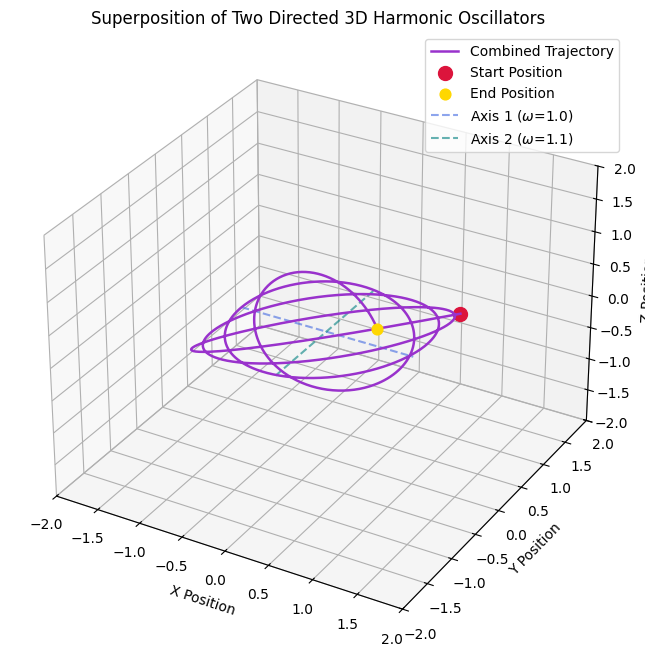

In [16]:

# Definition oscillation function based on Harmonic Oscillator equation: x(t) = A * cos(ωt + φ)
def get_oscillation_coords(t, direction_vec, omega, amplitude, phase=0.0):
    """Calculates the 3D position array over time for a single directed oscillation."""
    # Normalize direction vector
    unit_vec = direction_vec / np.linalg.norm(direction_vec)
    # Calculate scalar displacement over time
    s = amplitude * np.cos(omega * t + phase)
    # Project displacement onto 3D space (outer product to get shape (N, 3))
    return np.outer(s, unit_vec)


# Time array
t = np.linspace(0, 24, 1500)


# --- OSCILLATOR 1 PROPERTIES ---
vec1 = np.array([1.0, 0.0, 0.0])  # Primary direction
omega1 = 1.0  # Angular frequency 1
amp1 = 1.0  # Amplitude 1
phase1 = 0 # phase displacement


# --- OSCILLATOR 2 PROPERTIES ---
vec2 = np.array([0.0, 1.0, 0.0])  # Secondary direction
omega2 = 1.1  # Angular frequency 2 (Try 1.5 for a closed loop, 1.414 for an open path)
amp2 = 1.0  # Amplitude 2
phase2 = 0 # pi/2 phase displacement


# Calculate individual 3D position trajectories
r1 = get_oscillation_coords(t, vec1, omega1, amp1, phase1)
r2 = get_oscillation_coords(t, vec2, omega2, amp2, phase2)

# Vector addition to combine both forces
r_total = r1 + r2
x, y, z = r_total[:, 0], r_total[:, 1], r_total[:, 2]

# Set up 3D plotting
fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection="3d")

# Plot combined trajectory
ax.plot(x, y, z, label="Combined Trajectory", color="darkorchid", lw=1.8, zorder=3)

# Plot start and end points for visual anchors
ax.scatter(x[0], y[0], z[0], color="crimson", s=100, label="Start Position", zorder=4)
ax.scatter(x[-1], y[-1], z[-1], color="gold", s=60, label="End Position", zorder=4)

# Visual aid: Draw the two driving vector axes through the origin
ax.plot([-vec1[0], vec1[0]], [-vec1[1], vec1[1]], [-vec1[2], vec1[2]], 
        color="royalblue", linestyle="--", alpha=0.6, label=rf"Axis 1 ($\omega$={omega1})")
ax.plot([-vec2[0], vec2[0]], [-vec2[1], vec2[1]], [-vec2[2], vec2[2]], 
        color="teal", linestyle="--", alpha=0.6, label=rf"Axis 2 ($\omega$={omega2})")

# Labels and styling
ax.set_title("Superposition of Two Directed 3D Harmonic Oscillators", fontsize=12)
ax.set_xlabel("X Position")
ax.set_ylabel("Y Position")
ax.set_zlabel("Z Position")
ax.legend()

# Equalize axes bounding box limits
max_bound = amp1 + amp2
ax.set_xlim(-max_bound, max_bound)
ax.set_ylim(-max_bound, max_bound)
ax.set_zlim(-max_bound, max_bound)

plt.show()


## Oscillations for Vibrational Modes in a Molecule

Calling Hessian for BDT and running functions to determine coordinates of vibrational modes
Plotting the sum of oscillations

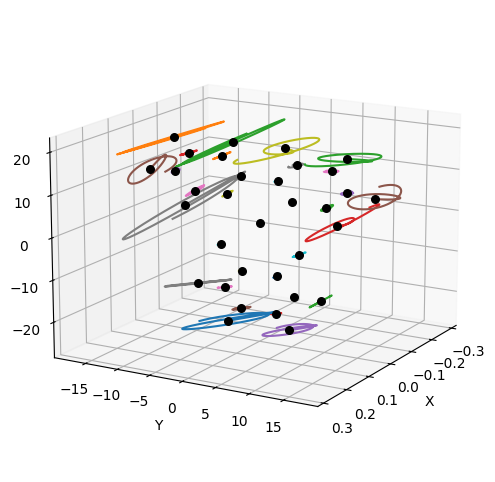

In [10]:
# Calling the Hessian Class for BptPtBDT
BDT = Hessian(r"C:\Users\apelr\OneDrive - University of New Mexico\Python Scripts\Josh_Scripts\BpyPtBDT_fine_vib.hess")
# Generating oscillation coordinates for two vibrational modes (7 and 9) with different magnitudes and phases
atomic_coords = BDT.hess_dict['atomic_coords'].reshape(-1, 3, 1)  # Reshape atomic coordinates for broadcasting
Q_vib1 = BDT.get_oscillation_coordinates(8, t=800, phase=0, mag_scaler=0.5) + atomic_coords
Q_vib2 = BDT.get_oscillation_coordinates(9, t=800, phase=0, mag_scaler=10.0) + atomic_coords
# Combining the two vibrational modes to create a superposition of oscillations
oscillation = Q_vib1 + Q_vib2


# 3D Plotting of the combined oscillation trajectories
fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(projection="3d")

for i in range(len(oscillation)):
  x = oscillation[i, 0, :]  # X trajectory over time for point i
  y = oscillation[i, 1, :]  # Y trajectory over time for point i
  z = oscillation[i, 2, :]  # Z trajectory over time for point i

  # Plot the full trajectory path
  ax.plot(x, y, z, label=f"Point {i+1}")

  # Mark the starting position (t = 0)
  ax.scatter(x[0], y[0], z[0], color="black", s=30)

# Rotate the view: azim controls horizontal rotation. 
ax.view_init(elev=15, azim=30)

ax.set_xlabel("X")
ax.set_ylabel("Y")
ax.set_zlabel("Z")
# ax.legend()
plt.show()